#Regresión logística bayesiana: ejemplo con datos real

In [29]:
library(MASS)
library(bayesplot)
library(ggplot2)
library(rstan)


In [30]:
nucleos <- parallel::detectCores()
if (is.na(nucleos)) nucleos <- 1
options(mc.cores = min(4, nucleos))
rstan::rstan_options(auto_write = TRUE)

In [31]:
data("Pima.tr", package = "MASS")

str(Pima.tr)
head(Pima.tr)

'data.frame':	200 obs. of  8 variables:
 $ npreg: int  5 7 5 0 0 5 3 1 3 2 ...
 $ glu  : int  86 195 77 165 107 97 83 193 142 128 ...
 $ bp   : int  68 70 82 76 60 76 58 50 80 78 ...
 $ skin : int  28 33 41 43 25 27 31 16 15 37 ...
 $ bmi  : num  30.2 25.1 35.8 47.9 26.4 35.6 34.3 25.9 32.4 43.3 ...
 $ ped  : num  0.364 0.163 0.156 0.259 0.133 ...
 $ age  : int  24 55 35 26 23 52 25 24 63 31 ...
 $ type : Factor w/ 2 levels "No","Yes": 1 2 1 1 1 2 1 1 1 2 ...


,npreg,glu,bp,skin,bmi,ped,age,type
,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<fct>
1,5,86,68,28,30.2,0.364,24,No
2,7,195,70,33,25.1,0.163,55,Yes
3,5,77,82,41,35.8,0.156,35,No
4,0,165,76,43,47.9,0.259,26,No
5,0,107,60,25,26.4,0.133,23,No
6,5,97,76,27,35.6,0.378,52,Yes


In [32]:
datos <- Pima.tr[, c("type", "glu", "bmi", "age")]

# Codificación binaria de la respuesta
datos$diabetes <- ifelse(datos$type == "Yes", 1, 0)

# Revisar valores faltantes
colSums(is.na(datos))

# Frecuencias de la respuesta
table(datos$type)
prop.table(table(datos$type))

type      glu      bmi      age diabetes 
       0        0        0        0        0


 No Yes 
132  68 


  No  Yes 
0.66 0.34 

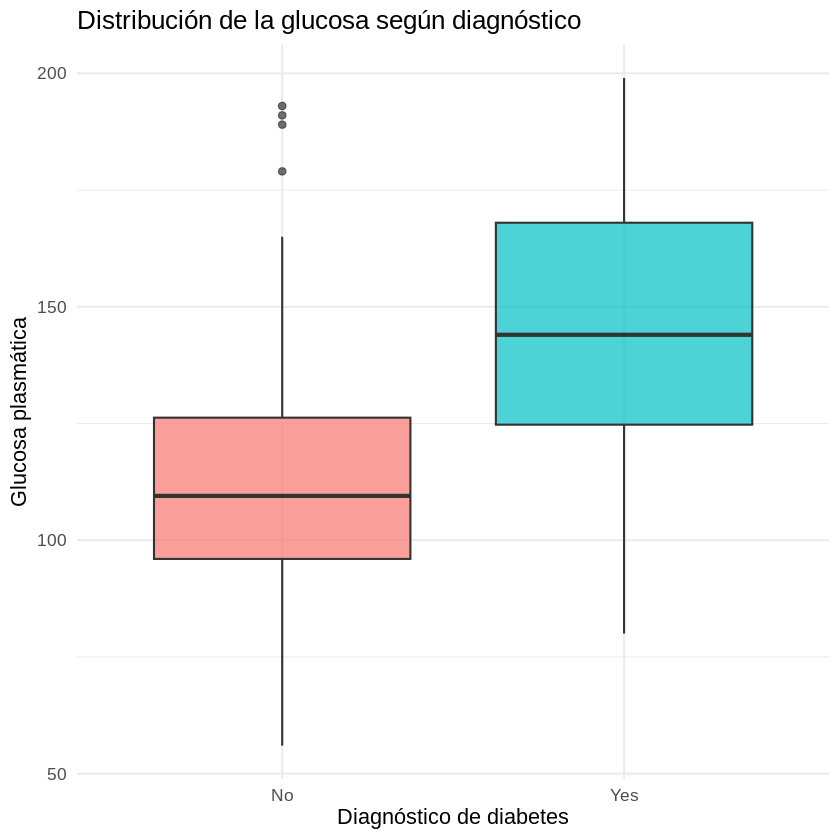

In [33]:
ggplot(datos, aes(x = type, y = glu, fill = type)) +
  geom_boxplot(alpha = 0.7, show.legend = FALSE) +
  labs(
    title = "Distribución de la glucosa según diagnóstico",
    x = "Diagnóstico de diabetes",
    y = "Glucosa plasmática"
  ) +
  theme_minimal(base_size = 13)

In [34]:
predictores <- c("glu", "bmi", "age")

medias <- vapply(datos[predictores], mean, numeric(1))
desviaciones <- vapply(datos[predictores], sd, numeric(1))

datos$glu_z <- (datos$glu - medias["glu"]) / desviaciones["glu"]
datos$bmi_z <- (datos$bmi - medias["bmi"]) / desviaciones["bmi"]
datos$age_z <- (datos$age - medias["age"]) / desviaciones["age"]

summary(datos[, c("glu_z", "bmi_z", "age_z")])

     glu_z             bmi_z              age_z        
 Min.   :-2.1464   Min.   :-2.30171   Min.   :-1.0123  
 1st Qu.:-0.7569   1st Qu.:-0.77240   1st Qu.:-0.8300  
 Median :-0.1096   Median : 0.07993   Median :-0.3745  
 Mean   : 0.0000   Mean   : 0.00000   Mean   : 0.0000  
 3rd Qu.: 0.6325   3rd Qu.: 0.68350   3rd Qu.: 0.6505  
 Max.   : 2.3693   Max.   : 2.54314   Max.   : 2.8145  

In [36]:
#install.packages(
#  "rstanarm",
#  repos = "https://cloud.r-project.org",
#  dependencies = TRUE
#)

In [37]:
library(rstanarm)

previa_coeficientes <- normal(
  location = 0,
  scale = 1,
  autoscale = FALSE
)

previa_intercepto <- normal(
  location = 0,
  scale = 2.5,
  autoscale = FALSE
)

In [38]:
set.seed(2026)

modelo_bayes <- stan_glm(
  diabetes ~ glu_z + bmi_z + age_z,
  data = datos,
  family = binomial(link = "logit"),
  prior = previa_coeficientes,
  prior_intercept = previa_intercepto,
  chains = 4,
  iter = 2000,
  warmup = 1000,
  seed = 2026,
  refresh = 0
)

print(modelo_bayes, digits = 3)

stan_glm
 family:       binomial [logit]
 formula:      diabetes ~ glu_z + bmi_z + age_z
 observations: 200
 predictors:   4
------
            Median MAD_SD
(Intercept) -0.921  0.192
glu_z        0.966  0.201
bmi_z        0.548  0.195
age_z        0.573  0.184

------
* For help interpreting the printed output see ?print.stanreg
* For info on the priors used see ?prior_summary.stanreg


In [39]:
parametros_diagnostico <- c(
  "(Intercept)", "glu_z", "bmi_z", "age_z"
)

resumen_diagnostico <- as.data.frame(
  summary(
    modelo_bayes,
    pars = parametros_diagnostico,
    probs = c(0.025, 0.50, 0.975)
  )
)

round(resumen_diagnostico, 3)

,mean,mcse,sd,2.5%,50%,97.5%,n_eff,Rhat
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),-0.924,0.003,0.194,-1.321,-0.921,-0.555,3706,1.000
glu_z,0.971,0.003,0.204,0.580,0.966,1.386,4134,1.000
bmi_z,0.553,0.003,0.194,0.189,0.548,0.951,3668,1.002
age_z,0.574,0.003,0.186,0.210,0.573,0.926,4139,1.001


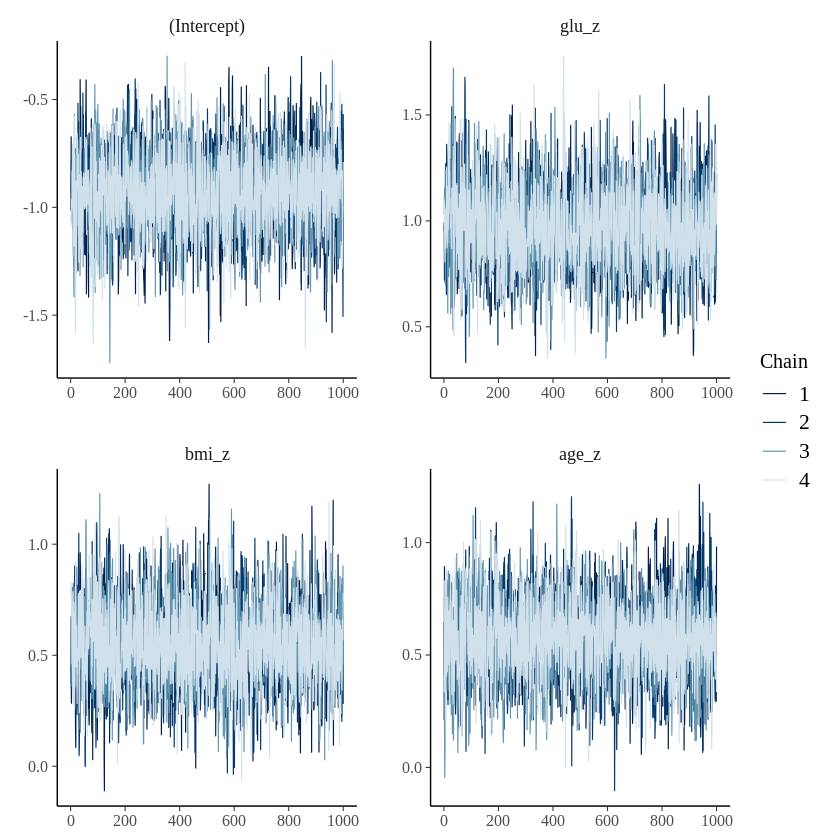

In [40]:
posterior_array <- as.array(modelo_bayes)

mcmc_trace(
  posterior_array,
  pars = c("(Intercept)", "glu_z", "bmi_z", "age_z")
)

In [41]:
muestras <- as.matrix(modelo_bayes)
parametros <- c("(Intercept)", "glu_z", "bmi_z", "age_z")
muestras_coef <- muestras[, parametros, drop = FALSE]

resumen_posterior <- data.frame(
  parametro = parametros,
  media = colMeans(muestras_coef),
  mediana = apply(muestras_coef, 2, median),
  limite_inferior_95 = apply(muestras_coef, 2, quantile, probs = 0.025),
  limite_superior_95 = apply(muestras_coef, 2, quantile, probs = 0.975),
  probabilidad_positivo = colMeans(muestras_coef > 0),
  OR_mediana = exp(apply(muestras_coef, 2, median)),
  OR_inferior_95 = exp(apply(muestras_coef, 2, quantile, probs = 0.025)),
  OR_superior_95 = exp(apply(muestras_coef, 2, quantile, probs = 0.975))
)

rownames(resumen_posterior) <- NULL
round(resumen_posterior[-1], 3)
resumen_posterior

media,mediana,limite_inferior_95,limite_superior_95,probabilidad_positivo,OR_mediana,OR_inferior_95,OR_superior_95
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
-0.924,-0.921,-1.321,-0.555,0.000,0.398,0.267,0.574
0.971,0.966,0.580,1.386,1.000,2.627,1.786,3.998
0.553,0.548,0.189,0.951,0.998,1.731,1.208,2.589
0.574,0.573,0.210,0.926,0.999,1.774,1.234,2.525


parametro,media,mediana,limite_inferior_95,limite_superior_95,probabilidad_positivo,OR_mediana,OR_inferior_95,OR_superior_95
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),-0.9239258,-0.9210103,-1.3205287,-0.5551068,0.00000,0.3981166,0.2669941,0.5740109
glu_z,0.9708230,0.9660110,0.5798004,1.3857338,1.00000,2.6274427,1.7856821,3.9977585
bmi_z,0.5526793,0.5484308,0.1889776,0.9513047,0.99825,1.7305354,1.2080139,2.5890855
age_z,0.5739746,0.5730999,0.2104221,0.9261383,0.99925,1.7737570,1.2341989,2.5247406


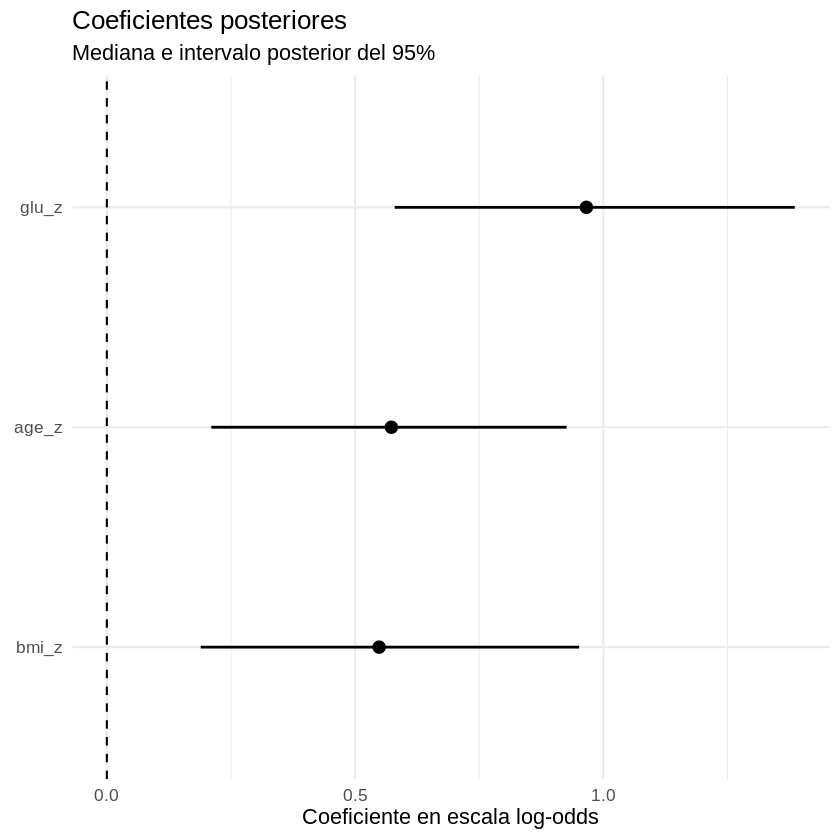

In [42]:
grafico_coef <- subset(
  resumen_posterior,
  parametro != "(Intercept)"
)

ggplot(
  grafico_coef,
  aes(x = mediana, y = reorder(parametro, mediana))
) +
  geom_vline(xintercept = 0, linetype = 2) +
  geom_segment(
    aes(
      x = limite_inferior_95,
      xend = limite_superior_95,
      yend = reorder(parametro, mediana)
    ),
    linewidth = 0.8
  ) +
  geom_point(size = 3) +
  labs(
    title = "Coeficientes posteriores",
    subtitle = "Mediana e intervalo posterior del 95%",
    x = "Coeficiente en escala log-odds",
    y = NULL
  ) +
  theme_minimal(base_size = 13)

In [43]:
nuevos <- data.frame(
  perfil = c("Perfil A", "Perfil B"),
  glu = c(100, 160),
  bmi = c(25, 35),
  age = c(30, 55)
)

nuevos$glu_z <- (nuevos$glu - medias["glu"]) / desviaciones["glu"]
nuevos$bmi_z <- (nuevos$bmi - medias["bmi"]) / desviaciones["bmi"]
nuevos$age_z <- (nuevos$age - medias["age"]) / desviaciones["age"]

probabilidades_posteriores <- posterior_linpred(
  modelo_bayes,
  newdata = nuevos,
  transform = TRUE
)

resumen_predicciones <- data.frame(
  nuevos[, c("perfil", "glu", "bmi", "age")],
  probabilidad_media = colMeans(probabilidades_posteriores),
  probabilidad_mediana = apply(probabilidades_posteriores, 2, median),
  limite_inferior_95 = apply(
    probabilidades_posteriores, 2, quantile, probs = 0.025
  ),
  limite_superior_95 = apply(
    probabilidades_posteriores, 2, quantile, probs = 0.975
  )
)

round(resumen_predicciones[-1], 3)
resumen_predicciones

Instead of posterior_linpred(..., transform=TRUE) please call posterior_epred(), which provides equivalent functionality.



,glu,bmi,age,probabilidad_media,probabilidad_mediana,limite_inferior_95,limite_superior_95
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,100,25,30,0.085,0.082,0.039,0.151
2,160,35,55,0.827,0.833,0.694,0.921


,perfil,glu,bmi,age,probabilidad_media,probabilidad_mediana,limite_inferior_95,limite_superior_95
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Perfil A,100,25,30,0.08540349,0.08224362,0.0390062,0.1509545
2,Perfil B,160,35,55,0.82690621,0.83288966,0.6940690,0.9212526


In [44]:
probabilidad_individual <- posterior_linpred(
  modelo_bayes,
  transform = TRUE
)

probabilidad_media <- colMeans(probabilidad_individual)
prediccion <- ifelse(probabilidad_media >= 0.5, 1, 0)

matriz_confusion <- table(
  Observado = datos$diabetes,
  Predicho = prediccion
)

matriz_confusion

exactitud_aparente <- mean(prediccion == datos$diabetes)
exactitud_aparente

Instead of posterior_linpred(..., transform=TRUE) please call posterior_epred(), which provides equivalent functionality.



         Predicho
Observado   0   1
        0 113  19
        1  29  39

[1] 0.76

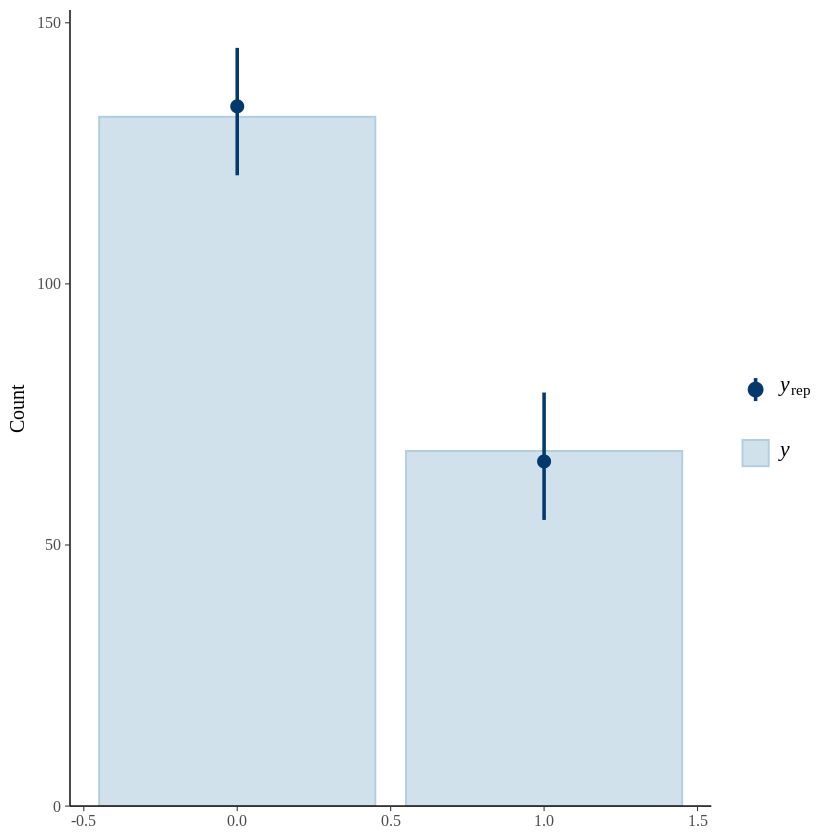

In [45]:
pp_check(modelo_bayes, plotfun = "bars", nreps = 50)

In [46]:
modelo_clasico <- glm(
  diabetes ~ glu_z + bmi_z + age_z,
  data = datos,
  family = binomial(link = "logit")
)

summary(modelo_clasico)


Call:
glm(formula = diabetes ~ glu_z + bmi_z + age_z, family = binomial(link = "logit"), 
    data = datos)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  -0.9243     0.1927  -4.798 1.61e-06 ***
glu_z         0.9769     0.2042   4.784 1.72e-06 ***
bmi_z         0.5632     0.1976   2.849  0.00438 ** 
age_z         0.5770     0.1863   3.098  0.00195 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 256.41  on 199  degrees of freedom
Residual deviance: 188.39  on 196  degrees of freedom
AIC: 196.39

Number of Fisher Scoring iterations: 5
